# 3. NCR zoom-in: does the national pattern hold inside Metro Manila?

**Question.** In Metro Manila, rich and poor neighbourhoods sit side by side, and outlets are everywhere. Does the national association between wealth and outlet density appear inside the region too?

**Unit.** The barangay (1,711 with people). NCR has only 121 RWI tiles, too few and too coarse to compare its neighbourhoods, so the tile version is run as a low-n check.

**Model.** The same NB2 count models, presence models and spatial checks as notebook 2, with these changes:

- **Intercepts.** City and municipality intercepts (17) instead of province intercepts.
- **Errors.** Clustered by the RWI tile each barangay's people mostly live in, since several barangays share one tile's wealth value.
- **Wealth unit.** Still one *national* tile SD, so the NCR ratios read on the same scale as the national ones.

In [1]:
import sys
from pathlib import Path

# The notebooks import their logic from src/: the shared helpers and the analysis functions.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "shared").is_dir())
for folder in ("src/shared", "src/02_data_analysis"):
    sys.path.insert(0, str(ROOT / folder))

import pandas as pd
from IPython.display import Image

from analysis_samples import RWI_SD, TABLES

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

import charts
import count_models as cm

## NCR barangays

In [2]:
ncr_barangays = cm.fit_scope("ncr_barangays")

NCR barangays: 1,711 units, 1,979 outlets
  count wealth only        rate ratio 0.948 (0.823-1.092)
  count + urban share      rate ratio 0.947 (0.822-1.090)


  spatial refit (25 eigenvectors) rate ratio 1.042 (0.878-1.237); residual Moran's I 0.0490 -> 0.0236
  count + shops            rate ratio 0.887 (0.753-1.044)


  spatial refit (25 eigenvectors) rate ratio 0.918 (0.754-1.118); residual Moran's I 0.0467 -> 0.0231
  count + shops and roads  rate ratio 0.934 (0.826-1.056)
  presence + urban share   odds ratio 1.202 (0.896-1.612) [9 units in areas with no variation dropped]


  presence + shops         odds ratio 1.225 (0.847-1.771) [9 units in areas with no variation dropped]
  LISA clusters: {'Not significant': 1509, 'Low-High': 73, 'Low-Low': 53, 'High-High': 48, 'High-Low': 28}


In [3]:
cm.summary(ncr_barangays)

,scope,unit,model,variant,estimate,n,wealth_ratio,ci_low,ci_high,p_value
0,NCR,barangay,count,wealth only,rate ratio,1711,0.948,0.823,1.092,0.4573
1,NCR,barangay,count,+ urban share,rate ratio,1711,0.947,0.822,1.090,0.4494
2,NCR,barangay,"count, spatial refit",+ urban share,rate ratio,1711,1.042,0.878,1.237,0.6370
3,NCR,barangay,count,+ shops,rate ratio,1711,0.887,0.753,1.044,0.1483
4,NCR,barangay,"count, spatial refit",+ shops,rate ratio,1711,0.918,0.754,1.118,0.3940
5,NCR,barangay,count,+ shops and roads,rate ratio,1711,0.934,0.826,1.056,0.2776
6,NCR,barangay,presence,+ urban share,odds ratio,1702,1.202,0.896,1.612,0.2190
7,NCR,barangay,presence,+ shops,odds ratio,1702,1.225,0.847,1.771,0.2814


**Reading.** Inside NCR there is no clear wealth gradient.
The rate ratio is 0.95 (0.82-1.09) without shops and 0.89 (0.75-1.04) with them, and every interval includes 1.
The presence odds ratios (about 1.2) are also inside noise.
Residuals cluster mildly (Moran's I about 0.05); a 25-eigenvector refit halves that and gives 1.04 and 0.92, still with intervals across 1.

## NCR tiles (low-n check)

In [4]:
ncr_tiles = cm.fit_scope("ncr_tiles")

NCR tiles: 121 units, 1,963 outlets
  count wealth only        rate ratio 0.965 (0.839-1.111)
  count + urban share      rate ratio 0.950 (0.826-1.092)
  count + shops            rate ratio 0.921 (0.818-1.037)
  count + shops and roads  rate ratio 0.941 (0.841-1.053)
  presence model not estimable: 114 of 121 units have an outlet


In [5]:
cm.summary(ncr_tiles)

,scope,unit,model,variant,estimate,n,wealth_ratio,ci_low,ci_high,p_value
0,NCR,tile,count,wealth only,rate ratio,121,0.965,0.839,1.111,0.6214
1,NCR,tile,count,+ urban share,rate ratio,121,0.950,0.826,1.092,0.4714
2,NCR,tile,count,+ shops,rate ratio,121,0.921,0.818,1.037,0.1719
3,NCR,tile,count,+ shops and roads,rate ratio,121,0.941,0.841,1.053,0.2870


**Reading.** The 121 NCR tiles agree with the barangays: 0.95 without shops and 0.92 with them, both with intervals across 1.
The presence model cannot be estimated, because 114 of the 121 tiles have an outlet.

## National and NCR side by side

In [6]:
tables = cm.write_tables([cm.load_part("national_tiles"), cm.load_part("national_barangays"),
                          ncr_barangays, ncr_tiles, cm.load_part("sensitivities")])
m = tables["models"]
main = m[m.model.isin(["count", "presence"]) & m.variant.isin(cm.MAIN)].copy()
main["ratio (95% CI)"] = main.apply(lambda r: f"{r.wealth_ratio:.2f} ({r.ci_low:.2f}-{r.ci_high:.2f})", axis=1)
main.pivot_table(index=["scope", "unit"], columns=["model", "variant"], values="ratio (95% CI)",
                 aggfunc="first", sort=False)

model                         count                            presence                  
variant               + urban share           + shops     + urban share           + shops
scope    unit                                                                            
National tile      2.13 (1.96-2.32)  1.17 (1.07-1.29)  2.18 (1.92-2.46)  1.59 (1.38-1.84)
         barangay  2.36 (2.22-2.52)  1.50 (1.39-1.61)  2.63 (2.47-2.81)  1.41 (1.32-1.51)
NCR      tile      0.95 (0.83-1.09)  0.92 (0.82-1.04)               NaN               NaN
         barangay  0.95 (0.82-1.09)  0.89 (0.75-1.04)  1.20 (0.90-1.61)  1.22 (0.85-1.77)

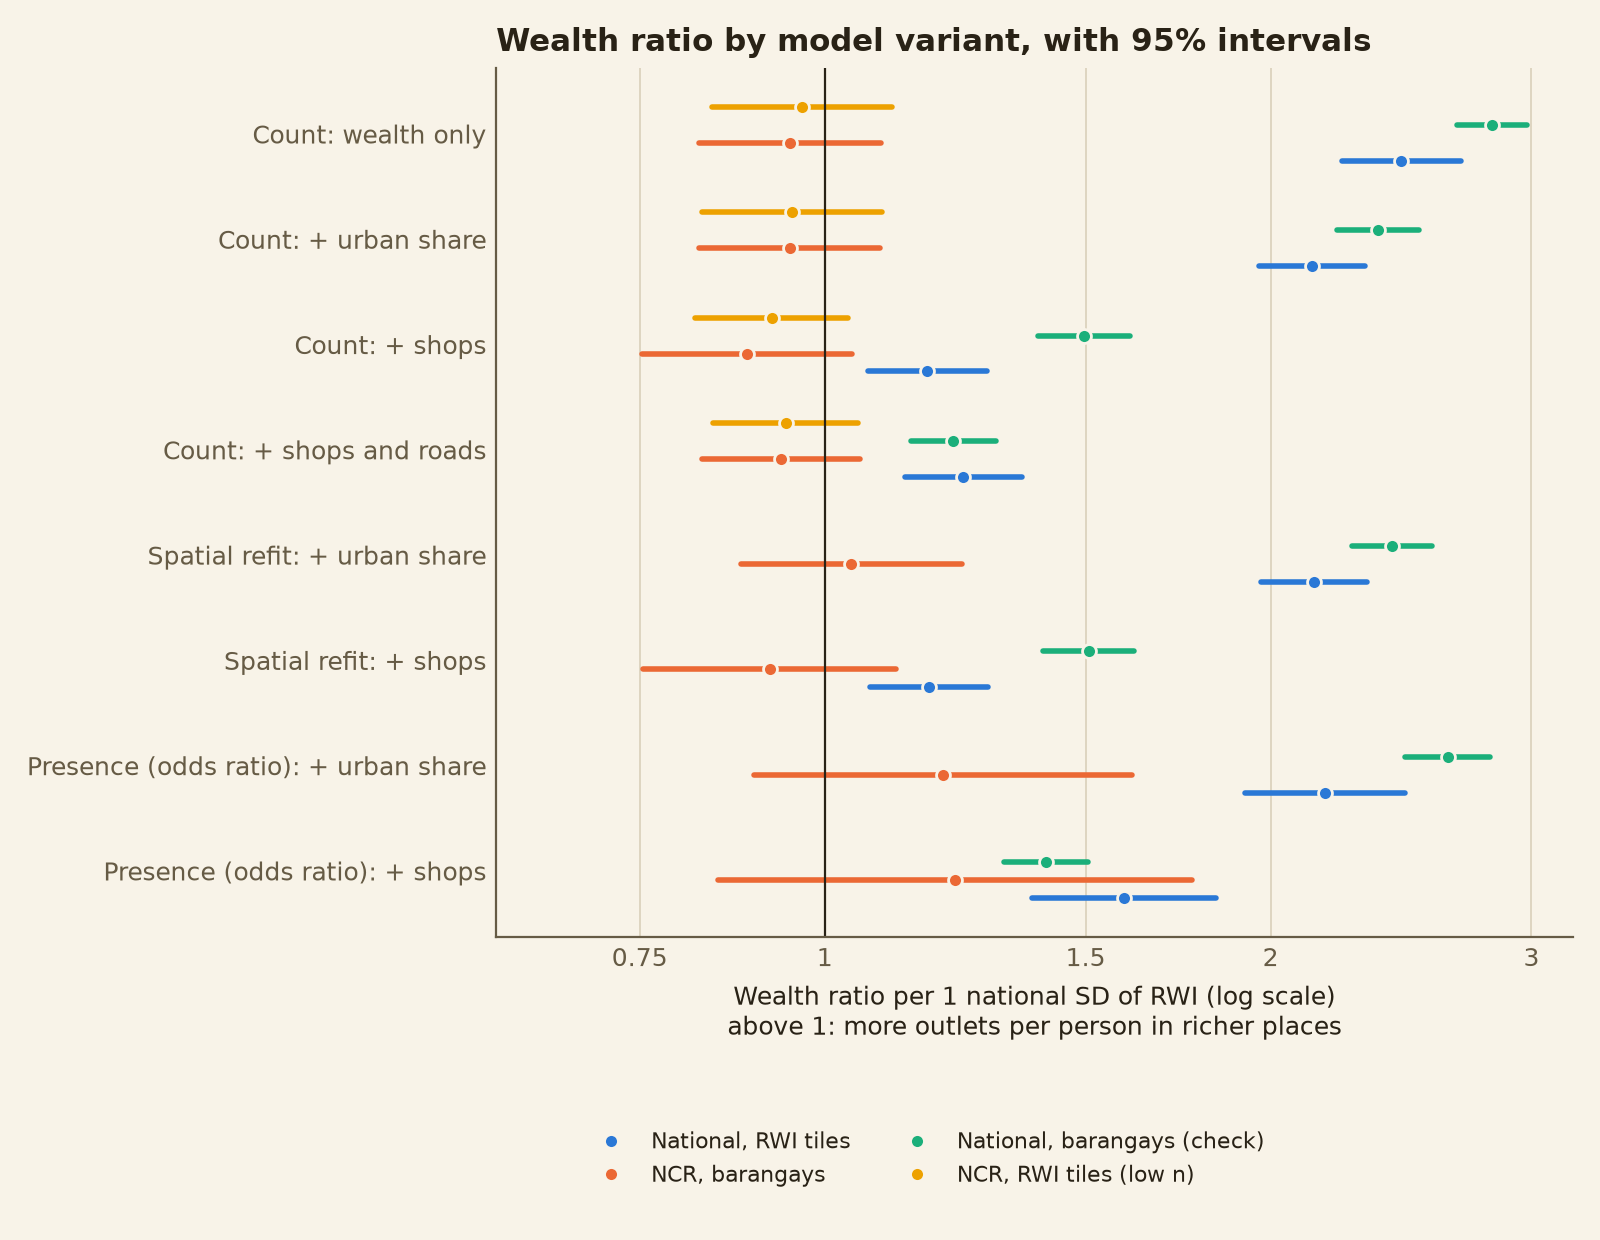

In [7]:
Image(charts.rate_ratio_chart(m), width=760)

**Reading.** Nationally, richer places have clearly more outlets per person in every variant, and the shops control shrinks the gap without closing it.
Inside NCR the association is flat in every variant: outlets are spread about evenly over richer and poorer barangays.
The national gradient therefore reads as a between-place pattern, with richer, more urban and more commercial parts of the country having more outlets, and it does not reappear among Metro Manila's neighbourhoods.
Step 4 discusses what this does and does not say about the "tax on the poor" claim.